# Diagnóstico de capacidad logística
**Pregunta:** el pronóstico, ¿propone volúmenes que el CD no puede despachar?, y si se recorta al tope de capacidad, ¿cuánto cambia el error?

`capacidad_logistica_generica.csv` entrega, por CD y día, el máximo de unidades despachables (`capacidad_maxima_unidades`). Aquí no se entrena nada: se compara el pronóstico y el real con ese tope y se mide el efecto de aplicar `min(predicción, capacidad)`. Las funciones están en `logforecast.capacity`.

Orden:
1. Cuánta capacidad se usa y qué tan seguido el real la alcanza.
2. Cuánto la excede el pronóstico base y en qué CD.
3. Efecto del recorte sobre el base y sobre los modelos de la Tarea 3.
4. Lectura: modelo vs regla de producción.

In [1]:
from logforecast import capacity as C
from logforecast import cv, diagnostics, io, plots
from logforecast import features as F
from logforecast.config import Settings

S = Settings.from_env()
frame = diagnostics.build_eval_frame(io.load_orders(S), io.load_forecasts(S))
cap = io.load_capacity(S)
d = C.attach_capacity(frame, cap)  # una fila por pronóstico, con su capacidad y los usos
print(f"{len(d)} pronósticos (4 horizontes) de {d[F.CD].nunique()} CD")

1380 pronósticos (4 horizontes) de 6 CD


## 1. Uso de la capacidad por CD
`cap. alta` es la capacidad de los días con tope mayor (en estos datos, los martes). Los días con real >= 90 % o > 100 % cuentan días distintos de despacho.

In [2]:
C.usage_by_cd(d)

,cap. normal,cap. alta,uso real medio (%),dias real >= 90% cap,dias real > cap,pron > cap (% filas),pron/cap cuando excede
centro_distribucion,,,,,,,
CD_CENTRO,1800.0,2250.0,80.79,11.0,2.0,39.13,1.17
CD_ESTE,960.0,1200.0,80.09,7.0,1.0,0.00,NaN
CD_NORTE,3600.0,4500.0,82.44,17.0,5.0,5.22,1.07
CD_OESTE,600.0,750.0,79.03,10.0,1.0,41.74,1.11
CD_PACIFICO,780.0,975.0,82.02,11.0,1.0,49.57,1.12
CD_SUR,2640.0,3300.0,81.01,8.0,2.0,0.00,NaN


## 2. Cuánto excede el pronóstico base la capacidad
Se cruza "el pronóstico excede el tope" con "el real excede el tope". Un pronóstico que excede el tope pero cuyo real no lo hace es una sobreestimación inejecutable.

In [3]:
display(C.exceed_matrix(d))
C.excess_rows_profile(d).round(2).to_frame("filas donde pron > cap")

col_0,real <= cap,real > cap,total
row_0,,,
pron <= cap,1042,26,1068
pron > cap,293,19,312


,filas donde pron > cap
filas,312.00
% de las filas,22.61
pron/cap medio,1.13
real/cap medio,0.87
% donde el real tambien excede,6.09
sesgo (real - pron)/real (%),-27.85
unidades pronosticadas sobre el tope,49005.69


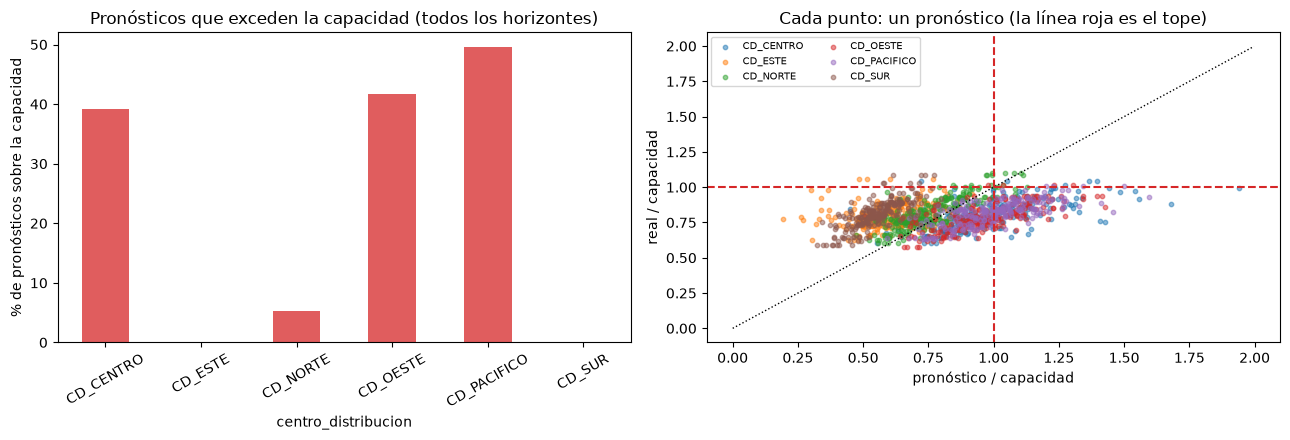

In [4]:
plots.plot_capacity(d)

### Por día de la semana

In [5]:
C.weekday_exceed(d)

,pron > cap (%),uso real medio (%),filas
lun,21.4,80.9,192
mar,26.0,84.4,192
mié,19.3,82.8,192
jue,29.2,81.8,192
vie,27.8,84.3,198
sáb,26.0,82.4,204
dom,9.5,70.5,210


## 3. Efecto del recorte a la capacidad
### 3.1 Sobre el pronóstico base (por CD y por horizonte)
WAPE del base con y sin `min(pron, capacidad)`. Negativo = el recorte mejora.

In [6]:
display(C.cap_effect(d, F.CD))
C.cap_effect(d, F.HOR)

,WAPE sin cap (%),WAPE con cap (%),dif (pp),filas recortadas (%)
centro_distribucion,,,,
CD_CENTRO,23.28,15.35,-7.93,39.13
CD_ESTE,25.86,25.86,0.00,0.00
CD_NORTE,9.82,9.73,-0.08,5.22
CD_OESTE,23.90,17.90,-6.01,41.74
CD_PACIFICO,22.15,14.98,-7.17,49.57
CD_SUR,31.56,31.56,0.00,0.00
GLOBAL,20.84,18.57,-2.28,22.61


,WAPE sin cap (%),WAPE con cap (%),dif (pp),filas recortadas (%)
horizonte,,,,
D+1,19.77,18.37,-1.40,24.29
D+2,20.30,18.53,-1.77,21.55
D+3,20.85,18.32,-2.53,21.35
D+4,22.53,19.06,-3.47,23.21
GLOBAL,20.84,18.57,-2.28,22.61


### 3.2 Sobre los modelos de la Tarea 3
Se usa el ElasticNet elegido en `04_validacion_cruzada_t3`, con su configuración fija (`cv.ELEGIDO`), y la referencia `ratio_mov14`, en CV de train y en test (mismo esquema del notebook 04). Si el modelo ya aprendió a no pasarse del tope, el recorte aporta poco.

In [7]:
AVAIL_LAG = 1
feat = F.build_features(frame, avail_lag=AVAIL_LAG)
study = cv.run_cv_study(feat, {cv.ELEGIDO: cv.chosen_spec()}, AVAIL_LAG)  # configuración fija del notebook 04
ho, _, _ = study.holdout()

modelo = f"{cv.ELEGIDO[0]}_cv"
res_train = {"base": study.refs["base"], study.ref_name: study.refs["ref"], modelo: study.res[cv.ELEGIDO]}
res_test = {k: ho[k] for k in res_train}

print("Train (CV, orígenes 22-ene a 13-feb):")
display(C.models_effect(res_train, cap))
print("Test (orígenes 14-feb a 28-feb):")
C.models_effect(res_test, cap)

Train (CV, orígenes 22-ene a 13-feb):


,WAPE sin cap (%),WAPE con cap (%),dif (pp),filas recortadas (%)
base,20.76,18.21,-2.55,23.45
ratio_mov14,9.46,8.62,-0.84,8.91
enet_cv,7.73,7.57,-0.16,2.13


Test (orígenes 14-feb a 28-feb):


,WAPE sin cap (%),WAPE con cap (%),dif (pp),filas recortadas (%)
base,20.31,18.18,-2.14,23.46
ratio_mov14,9.17,8.01,-1.16,11.73
enet_cv,7.26,7.26,-0.00,2.47


## 4. Lectura
- **El base se pasa del tope con frecuencia y de forma concentrada:** más de un 20 % de los pronósticos excede la capacidad, casi todos en `CD_CENTRO`, `CD_OESTE` y `CD_PACIFICO`. En `CD_ESTE` y `CD_SUR` el base nunca la excede. Cuando excede, el real casi nunca lo hace (solo un ~6 %): son sobreestimaciones, no demanda real que no se pueda atender.
- **El real casi no satura:** el uso medio es ~80 % y solo en 13 de 360 CD-día supera el tope (6 en CD_NORTE). La tabla de la sección 1 muestra 12 de 354 porque solo cubre los despachos con pronóstico (desde el 2-ene); el que falta es CD_NORTE el 1-ene. Con tan pocos casos no se puede afirmar que el real esté censurado por capacidad.
- **El recorte mejora al base** (alrededor de 2 puntos de WAPE) y más a horizontes lejanos, porque ahí el base se pasa más. Pero en gran parte reemplaza lo que ya hace la corrección: en esos CD el base sobreestima.
- **En los modelos el efecto se diluye:** la referencia `ratio_mov14` mejora algo con el recorte (−0,84 pp en train y −1,16 pp en test) y el ElasticNet casi nada (−0,16 y 0,00 pp), porque solo un ~2 % de sus pronósticos supera el tope (2,1 % en train y 2,5 % en test, contra ~23 % del base). Es decir, el modelo ya incorpora lo que el recorte aportaría al base.
- **Conclusión:** la capacidad no mejora los modelos de forma apreciable (no justifica ser feature ni cambiar la elección del modelo), pero sí es una **regla de seguridad de producción**: garantiza que ningún pronóstico publicado supere lo despachable, sin costo en error. Recomendación: que el endpoint de inferencia devuelva la `capacidad_maxima` del día y un indicador `alerta_capacidad` (OK / CERCA / EXCEDE / SIN_CAPACIDAD) sin modificar las unidades, y que el consumidor decida si recorta o reasigna. Registrar cuántas veces salta `EXCEDE` sirve además como señal de que el modelo se está desviando. Está implementado en `capacity.capacity_alert` y se usa desde `pipeline.predict` y el handler de Lambda.

**Limitaciones:** son ~2 meses; la capacidad solo tiene dos valores por CD y no se sabe por qué cambia (solo se observa que es en martes); el ElasticNet se eligió (notebook 04) con los mismos orígenes de train que se usan aquí para medir el recorte.